In [ ]:
try:
    import google.colab  # noqa: F401
except ImportError:
    import matplotlib
    matplotlib.use("Agg")

from pathlib import Path

# Colab reads the project from Google Drive.
# Anywhere else, use the local project folder that contains data/raw.
use_google_drive = False
try:
    from google.colab import drive
    use_google_drive = True
except ImportError:
    use_google_drive = False

if use_google_drive:
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/SIADS_696_project')
else:
    search_folders = [Path.cwd(), *Path.cwd().parents]
    try:
        search_folders.extend(Path(__file__).resolve().parents)
    except NameError:
        pass
    team_repo = Path.home() / "Documents" / "SIADS696-Team06-Fall26"
    if team_repo not in search_folders:
        search_folders.append(team_repo)

    PROJECT_DIR = None
    for folder in search_folders:
        clinical_path = folder / "data" / "raw" / "TCGA-CDR-SupplementalTableS1.xlsx"
        immune_path = folder / "data" / "raw" / "TCGA.Kallisto.fullIDs.cibersort.relative.tsv"
        if clinical_path.exists() and immune_path.exists():
            PROJECT_DIR = folder
            break
    if PROJECT_DIR is None:
        raise FileNotFoundError("Could not find the two data files in data/raw.")

RAW_DIR = PROJECT_DIR / 'data' / "raw"
PROCESSED_DIR = PROJECT_DIR / 'data' / "processed"

FIGURE_DIR = PROJECT_DIR / 'outputs' / 'figures'
TABLE_DIR = PROJECT_DIR / 'outputs' / 'tables'

# Create output folders if they do not already exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Raw data:", RAW_DIR)
print("Processed data:", PROCESSED_DIR)



try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
except ImportError:
    pass


Mounted at /content/drive


In [ ]:
import os
from pathlib import Path

target_files = {
    "kirc_patient_level_merged.csv",
    "kirc_supervised_3year.csv",
}

bases = [
    "/content/drive/MyDrive",
    "/content/drive/.shortcut-targets-by-id",
    "/content/drive/Shareddrives",
]

if Path("/content/drive").exists():
    for base in bases:
        print(f"\nSearching: {base}")
        if not Path(base).exists():
            continue
        for root, dirs, files in os.walk(base):
            for name in files:
                if name in target_files:
                    print("FOUND:", os.path.join(root, name))
else:
    print("Not running in Colab, so the Drive search is skipped.")



Searching: /content/drive/MyDrive
FOUND: /content/drive/MyDrive/SIADS_696_project/data/processed/kirc_patient_level_merged.csv
FOUND: /content/drive/MyDrive/SIADS_696_project/data/processed/kirc_supervised_3year.csv

Searching: /content/drive/.shortcut-targets-by-id

Searching: /content/drive/Shareddrives


In [ ]:
from pathlib import Path
import pandas as pd

shortcut = Path(
    "/content/drive/.shortcut-targets-by-id/1Etb6PgEnIDI846xzjqpiUS4nA8LNJh3f/SIADS_696_project"
)
if shortcut.exists():
    PROJECT_DIR = shortcut

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

FIGURE_DIR = PROJECT_DIR / "outputs" / "figures"
TABLE_DIR = PROJECT_DIR / "outputs" / "tables"


In [ ]:
print(PROCESSED_DIR)

for f in PROCESSED_DIR.iterdir():
    print(f.name)

/content/drive/.shortcut-targets-by-id/1Etb6PgEnIDI846xzjqpiUS4nA8LNJh3f/SIADS_696_project/data/processed
kirc_patient_level_merged.csv
kirc_supervised_3year.csv


In [ ]:

# download the supervised dataset for training, the data set  contain 404 samples

merged = pd.read_csv(
    PROCESSED_DIR / "kirc_patient_level_merged.csv"
)

supervised = pd.read_csv(
    PROCESSED_DIR / "kirc_supervised_3year.csv"
)

In [ ]:
merged

,patient_id,age_at_initial_pathologic_diagnosis,gender,ajcc_pathologic_tumor_stage,histological_grade,OS,OS.time,SampleID,CancerType,B.cells.naive,...,Mast.cells.resting,Mast.cells.activated,Eosinophils,Neutrophils,P.value,Correlation,RMSE,sample_barcode,sample_type,survival_3y
0,TCGA-3Z-A93Z,69.0,MALE,Stage I,G2,0.0,385.0,TCGA.3Z.A93Z.01A.11R.A37O.07,KIRC,0.076633,...,0.030092,0.000000,0.0,0.000000,0.002,0.324338,0.951231,TCGA-3Z-A93Z-01A-11R-A37O-07,1,NaN
1,TCGA-6D-AA2E,68.0,FEMALE,Stage I,G2,0.0,362.0,TCGA.6D.AA2E.01A.11R.A37O.07,KIRC,0.139206,...,0.000000,0.031692,0.0,0.000000,0.000,0.401314,0.920127,TCGA-6D-AA2E-01A-11R-A37O-07,1,NaN
2,TCGA-A3-3306,67.0,MALE,Stage I,G3,0.0,1120.0,TCGA.A3.3306.01A.01R.0864.07,KIRC,0.000000,...,0.021969,0.000000,0.0,0.017851,0.056,0.134451,1.035928,TCGA-A3-3306-01A-01R-0864-07,1,1.0
3,TCGA-A3-3307,66.0,MALE,Stage III,G3,0.0,1436.0,TCGA.A3.3307.01A.01R.0864.07,KIRC,0.005329,...,0.018104,0.000000,0.0,0.007902,0.006,0.286399,0.970391,TCGA-A3-3307-01A-01R-0864-07,1,1.0
4,TCGA-A3-3308,77.0,FEMALE,Stage III,G2,0.0,16.0,TCGA.A3.3308.01A.02R.1325.07,KIRC,0.032737,...,0.027088,0.000000,0.0,0.000000,0.036,0.160134,1.024322,TCGA-A3-3308-01A-02R-1325-07,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528,TCGA-MM-A563,41.0,MALE,NaN,G2,0.0,591.0,TCGA.MM.A563.01A.11R.A266.07,KIRC,0.039347,...,0.045641,0.000000,0.0,0.000000,0.008,0.234513,0.987352,TCGA-MM-A563-01A-11R-A266-07,1,NaN
529,TCGA-MM-A564,68.0,MALE,Stage II,G2,0.0,607.0,TCGA.MM.A564.01A.11R.A266.07,KIRC,0.000000,...,0.105049,0.000000,0.0,0.000000,0.020,0.188133,1.016900,TCGA-MM-A564-01A-11R-A266-07,1,NaN
530,TCGA-MM-A84U,58.0,FEMALE,Stage I,G2,0.0,700.0,TCGA.MM.A84U.01A.11R.A37O.07,KIRC,0.026192,...,0.059373,0.000000,0.0,0.000000,0.024,0.178478,1.014154,TCGA-MM-A84U-01A-11R-A37O-07,1,NaN
531,TCGA-MW-A4EC,72.0,FEMALE,Stage I,G2,0.0,498.0,TCGA.MW.A4EC.01A.11R.A266.07,KIRC,0.000000,...,0.031670,0.005660,0.0,0.011586,0.010,0.219536,0.993912,TCGA-MW-A4EC-01A-11R-A266-07,1,NaN


In [ ]:
supervised

,patient_id,age_at_initial_pathologic_diagnosis,gender,ajcc_pathologic_tumor_stage,histological_grade,OS,OS.time,SampleID,CancerType,B.cells.naive,...,Mast.cells.resting,Mast.cells.activated,Eosinophils,Neutrophils,P.value,Correlation,RMSE,sample_barcode,sample_type,survival_3y
0,TCGA-A3-3306,67.0,MALE,Stage I,G3,0.0,1120.0,TCGA.A3.3306.01A.01R.0864.07,KIRC,0.000000,...,0.021969,0.000000,0.000000,0.017851,0.056,0.134451,1.035928,TCGA-A3-3306-01A-01R-0864-07,1,1
1,TCGA-A3-3307,66.0,MALE,Stage III,G3,0.0,1436.0,TCGA.A3.3307.01A.01R.0864.07,KIRC,0.005329,...,0.018104,0.000000,0.000000,0.007902,0.006,0.286399,0.970391,TCGA-A3-3307-01A-01R-0864-07,1,1
2,TCGA-A3-3311,57.0,MALE,Stage I,G2,1.0,1191.0,TCGA.A3.3311.01A.02R.1325.07,KIRC,0.099994,...,0.000000,0.004591,0.000000,0.008158,0.020,0.188282,1.009759,TCGA-A3-3311-01A-02R-1325-07,1,1
3,TCGA-A3-3313,59.0,MALE,Stage I,G3,1.0,735.0,TCGA.A3.3313.01A.02R.1325.07,KIRC,0.022534,...,0.025308,0.000000,0.030918,0.000000,0.060,0.129758,1.035706,TCGA-A3-3313-01A-02R-1325-07,1,0
4,TCGA-A3-3316,57.0,MALE,Stage II,G3,0.0,1493.0,TCGA.A3.3316.01A.01R.0864.07,KIRC,0.022203,...,0.000000,0.072195,0.000000,0.032183,0.008,0.270477,0.984255,TCGA-A3-3316-01A-01R-0864-07,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,TCGA-DV-A4W0,55.0,MALE,Stage I,G3,0.0,2470.0,TCGA.DV.A4W0.01A.11R.A266.07,KIRC,0.010990,...,0.026607,0.000000,0.000000,0.000000,0.056,0.134197,1.043636,TCGA-DV-A4W0-01A-11R-A266-07,1,1
400,TCGA-G6-A5PC,54.0,FEMALE,Stage IV,G4,1.0,242.0,TCGA.G6.A5PC.01A.11R.A33J.07,KIRC,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.008,0.251017,1.009122,TCGA-G6-A5PC-01A-11R-A33J-07,1,0
401,TCGA-G6-A8L6,55.0,MALE,Stage IV,G3,1.0,313.0,TCGA.G6.A8L6.01A.11R.A37O.07,KIRC,0.017519,...,0.013755,0.000000,0.000000,0.000000,0.034,0.161599,1.019592,TCGA-G6-A8L6-01A-11R-A37O-07,1,0
402,TCGA-G6-A8L7,81.0,FEMALE,Stage I,G3,0.0,2133.0,TCGA.G6.A8L7.01A.11R.A37O.07,KIRC,0.000000,...,0.039586,0.000000,0.000000,0.000000,0.040,0.153722,1.073173,TCGA-G6-A8L7-01A-11R-A37O-07,1,1


In [ ]:

# data cleaning and drop columns that are irrelevent for training
supervised = pd.read_csv(
    PROCESSED_DIR / "kirc_supervised_3year.csv"
)
supervised = supervised.drop(
    columns=['patient_id', "OS", "OS.time", "SampleID", "CancerType", "sample_barcode",'P.value', 'Correlation', 'RMSE', 'sample_type']
)


In [ ]:

supervised.columns

Index(['age_at_initial_pathologic_diagnosis', 'gender',
       'ajcc_pathologic_tumor_stage', 'histological_grade', 'B.cells.naive',
       'B.cells.memory', 'Plasma.cells', 'T.cells.CD8', 'T.cells.CD4.naive',
       'T.cells.CD4.memory.resting', 'T.cells.CD4.memory.activated',
       'T.cells.follicular.helper', 'T.cells.regulatory..Tregs.',
       'T.cells.gamma.delta', 'NK.cells.resting', 'NK.cells.activated',
       'Monocytes', 'Macrophages.M0', 'Macrophages.M1', 'Macrophages.M2',
       'Dendritic.cells.resting', 'Dendritic.cells.activated',
       'Mast.cells.resting', 'Mast.cells.activated', 'Eosinophils',
       'Neutrophils', 'survival_3y'],
      dtype='object')

In [ ]:
supervised[['ajcc_pathologic_tumor_stage', 'histological_grade','survival_3y' ]]

,ajcc_pathologic_tumor_stage,histological_grade,survival_3y
0,Stage I,G3,1
1,Stage III,G3,1
2,Stage I,G2,1
3,Stage I,G3,0
4,Stage II,G3,1
...,...,...,...
399,Stage I,G3,1
400,Stage IV,G4,0
401,Stage IV,G3,0
402,Stage I,G3,1


In [ ]:

# one hot encoding
import pandas as pd
try:
    from google.colab import files
except ImportError:
    files = None

# # 1. Load supervised dataset
# supervised = pd.read_csv(
#     "/content/kirc_supervised_3year.csv"
# )

# 2. Select categorical variables
categorical_cols = [
    "gender",
    "ajcc_pathologic_tumor_stage",
    "histological_grade"
]

# 3. Perform one-hot encoding
one_hot = pd.get_dummies(
    supervised[categorical_cols],
    prefix=categorical_cols,
    dtype=int,
    drop_first=False
)

# 4. Add one-hot columns to original supervised table
supervised_encoded = pd.concat(
    [supervised.drop(columns=categorical_cols), one_hot],
    axis=1
)

# 5. Verify results
print("Original shape:", supervised.shape)
print("Encoded shape:", supervised_encoded.shape)

display(supervised_encoded.head(10))

# 6. Export full dataset to Excel
filename = "KIRC_Supervised_OneHot_Encoded.xlsx"

supervised_encoded.to_excel(
    filename,
    index=False
)

# 7. Download Excel
print("Saved", filename) if files is None else files.download(filename)


Original shape: (404, 27)
Encoded shape: (404, 35)


,age_at_initial_pathologic_diagnosis,gender,ajcc_pathologic_tumor_stage,histological_grade,B.cells.naive,B.cells.memory,Plasma.cells,T.cells.CD8,T.cells.CD4.naive,T.cells.CD4.memory.resting,...,Neutrophils,survival_3y,ajcc_pathologic_tumor_stage_Stage I,ajcc_pathologic_tumor_stage_Stage II,ajcc_pathologic_tumor_stage_Stage III,ajcc_pathologic_tumor_stage_Stage IV,histological_grade_G1,histological_grade_G2,histological_grade_G3,histological_grade_G4
0,67.0,MALE,Stage I,G3,0.000000,0.017880,0.002659,0.113901,0.0,0.236851,...,0.017851,1,1,0,0,0,0,0,1,0
1,66.0,MALE,Stage III,G3,0.005329,0.000000,0.002634,0.257239,0.0,0.083907,...,0.007902,1,0,0,1,0,0,0,1,0
2,57.0,MALE,Stage I,G2,0.099994,0.000000,0.027638,0.133912,0.0,0.178104,...,0.008158,1,1,0,0,0,0,1,0,0
3,59.0,MALE,Stage I,G3,0.022534,0.033735,0.000000,0.047803,0.0,0.148167,...,0.000000,0,1,0,0,0,0,0,1,0
4,57.0,MALE,Stage II,G3,0.022203,0.000000,0.006868,0.052009,0.0,0.056278,...,0.032183,1,0,1,0,0,0,0,1,0
5,67.0,MALE,Stage II,G2,0.000000,0.019449,0.012053,0.213135,0.0,0.073592,...,0.004361,1,0,1,0,0,0,1,0,0
6,70.0,MALE,Stage I,G2,0.022939,0.000000,0.066049,0.192548,0.0,0.136558,...,0.013746,1,1,0,0,0,0,1,0,0
7,52.0,FEMALE,Stage I,G1,0.000000,0.000000,0.027624,0.138742,0.0,0.255883,...,0.030964,1,1,0,0,0,1,0,0,0
8,51.0,MALE,Stage I,G2,0.000000,0.015964,0.021897,0.036689,0.0,0.151226,...,0.002990,1,1,0,0,0,0,1,0,0
9,53.0,MALE,Stage I,G1,0.020156,0.000000,0.020922,0.105638,0.0,0.222288,...,0.006660,1,1,0,0,0,1,0,0,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
supervised_encoded

,age_at_initial_pathologic_diagnosis,gender,ajcc_pathologic_tumor_stage,histological_grade,B.cells.naive,B.cells.memory,Plasma.cells,T.cells.CD8,T.cells.CD4.naive,T.cells.CD4.memory.resting,...,Neutrophils,survival_3y,ajcc_pathologic_tumor_stage_Stage I,ajcc_pathologic_tumor_stage_Stage II,ajcc_pathologic_tumor_stage_Stage III,ajcc_pathologic_tumor_stage_Stage IV,histological_grade_G1,histological_grade_G2,histological_grade_G3,histological_grade_G4
0,67.0,MALE,Stage I,G3,0.000000,0.017880,0.002659,0.113901,0.0,0.236851,...,0.017851,1,1,0,0,0,0,0,1,0
1,66.0,MALE,Stage III,G3,0.005329,0.000000,0.002634,0.257239,0.0,0.083907,...,0.007902,1,0,0,1,0,0,0,1,0
2,57.0,MALE,Stage I,G2,0.099994,0.000000,0.027638,0.133912,0.0,0.178104,...,0.008158,1,1,0,0,0,0,1,0,0
3,59.0,MALE,Stage I,G3,0.022534,0.033735,0.000000,0.047803,0.0,0.148167,...,0.000000,0,1,0,0,0,0,0,1,0
4,57.0,MALE,Stage II,G3,0.022203,0.000000,0.006868,0.052009,0.0,0.056278,...,0.032183,1,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,55.0,MALE,Stage I,G3,0.010990,0.002781,0.039073,0.113058,0.0,0.079337,...,0.000000,1,1,0,0,0,0,0,1,0
400,54.0,FEMALE,Stage IV,G4,0.000000,0.000000,0.077358,0.431488,0.0,0.000000,...,0.000000,0,0,0,0,1,0,0,0,1
401,55.0,MALE,Stage IV,G3,0.017519,0.000000,0.050443,0.117698,0.0,0.106270,...,0.000000,0,0,0,0,1,0,0,1,0
402,81.0,FEMALE,Stage I,G3,0.000000,0.025239,0.041715,0.330335,0.0,0.000000,...,0.000000,1,1,0,0,0,0,0,1,0


In [ ]:
supervised_encoded.columns

Index(['age_at_initial_pathologic_diagnosis', 'gender',
       'ajcc_pathologic_tumor_stage', 'histological_grade', 'B.cells.naive',
       'B.cells.memory', 'Plasma.cells', 'T.cells.CD8', 'T.cells.CD4.naive',
       'T.cells.CD4.memory.resting', 'T.cells.CD4.memory.activated',
       'T.cells.follicular.helper', 'T.cells.regulatory..Tregs.',
       'T.cells.gamma.delta', 'NK.cells.resting', 'NK.cells.activated',
       'Monocytes', 'Macrophages.M0', 'Macrophages.M1', 'Macrophages.M2',
       'Dendritic.cells.resting', 'Dendritic.cells.activated',
       'Mast.cells.resting', 'Mast.cells.activated', 'Eosinophils',
       'Neutrophils', 'survival_3y', 'ajcc_pathologic_tumor_stage_Stage I',
       'ajcc_pathologic_tumor_stage_Stage II',
       'ajcc_pathologic_tumor_stage_Stage III',
       'ajcc_pathologic_tumor_stage_Stage IV', 'histological_grade_G1',
       'histological_grade_G2', 'histological_grade_G3',
       'histological_grade_G4'],
      dtype='object')

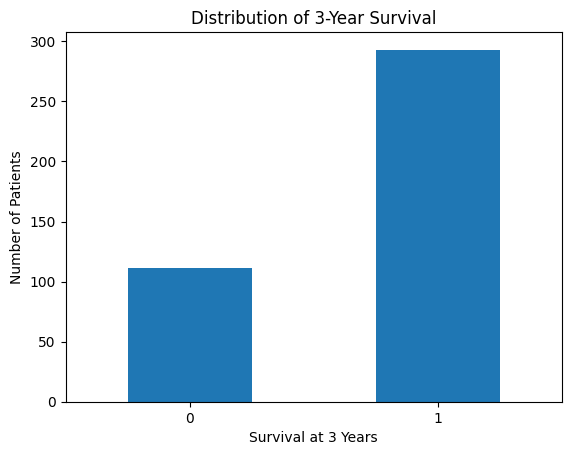

In [ ]:
import matplotlib.pyplot as plt

target=supervised_encoded['survival_3y']

target.value_counts().sort_index().plot(kind="bar")

plt.xlabel("Survival at 3 Years")
plt.ylabel("Number of Patients")
plt.title("Distribution of 3-Year Survival")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# %pip install imbalanced-learn


In [ ]:
import numpy as np
import sklearn as sk
from sklearn import metrics
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import validation_curve
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
#from imblearn.over_sampling import ADASYN
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
from sklearn.model_selection import train_test_split

X = supervised_encoded.drop(columns=['survival_3y'])
y = target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=72,
    stratify=y
)

In [ ]:
X_train


,age_at_initial_pathologic_diagnosis,gender,ajcc_pathologic_tumor_stage,histological_grade,B.cells.naive,B.cells.memory,Plasma.cells,T.cells.CD8,T.cells.CD4.naive,T.cells.CD4.memory.resting,...,Eosinophils,Neutrophils,ajcc_pathologic_tumor_stage_Stage I,ajcc_pathologic_tumor_stage_Stage II,ajcc_pathologic_tumor_stage_Stage III,ajcc_pathologic_tumor_stage_Stage IV,histological_grade_G1,histological_grade_G2,histological_grade_G3,histological_grade_G4
216,73.0,FEMALE,Stage IV,G4,0.006594,0.000000,0.000000,0.151349,0.000000,0.071258,...,0.000000,0.000000,0,0,0,1,0,0,0,1
267,58.0,FEMALE,Stage I,G2,0.014361,0.000000,0.000000,0.131513,0.000000,0.215721,...,0.000000,0.010242,1,0,0,0,0,1,0,0
144,50.0,MALE,Stage I,G2,0.059895,0.000000,0.011771,0.297170,0.000000,0.110004,...,0.000000,0.006586,1,0,0,0,0,1,0,0
387,51.0,MALE,Stage I,G3,0.085038,0.000000,0.100712,0.047689,0.000000,0.280144,...,0.000000,0.005353,1,0,0,0,0,0,1,0
340,54.0,MALE,Stage I,G3,0.029036,0.000000,0.025804,0.208393,0.000000,0.125411,...,0.000000,0.009453,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,69.0,MALE,Stage III,G4,0.020377,0.000000,0.040405,0.338328,0.000000,0.000000,...,0.000000,0.014182,0,0,1,0,0,0,0,1
211,42.0,MALE,Stage I,G3,0.081016,0.000000,0.054697,0.114994,0.000000,0.219614,...,0.000000,0.006075,1,0,0,0,0,0,1,0
398,59.0,MALE,Stage IV,G4,0.000677,0.000739,0.019023,0.332466,0.000000,0.000000,...,0.000000,0.014674,0,0,0,1,0,0,0,1
13,79.0,MALE,Stage I,G2,0.000000,0.017235,0.003226,0.000000,0.017178,0.201263,...,0.015008,0.032633,1,0,0,0,0,1,0,0


In [ ]:
X_train.columns

Index(['age_at_initial_pathologic_diagnosis', 'gender',
       'ajcc_pathologic_tumor_stage', 'histological_grade', 'B.cells.naive',
       'B.cells.memory', 'Plasma.cells', 'T.cells.CD8', 'T.cells.CD4.naive',
       'T.cells.CD4.memory.resting', 'T.cells.CD4.memory.activated',
       'T.cells.follicular.helper', 'T.cells.regulatory..Tregs.',
       'T.cells.gamma.delta', 'NK.cells.resting', 'NK.cells.activated',
       'Monocytes', 'Macrophages.M0', 'Macrophages.M1', 'Macrophages.M2',
       'Dendritic.cells.resting', 'Dendritic.cells.activated',
       'Mast.cells.resting', 'Mast.cells.activated', 'Eosinophils',
       'Neutrophils', 'ajcc_pathologic_tumor_stage_Stage I',
       'ajcc_pathologic_tumor_stage_Stage II',
       'ajcc_pathologic_tumor_stage_Stage III',
       'ajcc_pathologic_tumor_stage_Stage IV', 'histological_grade_G1',
       'histological_grade_G2', 'histological_grade_G3',
       'histological_grade_G4'],
      dtype='object')

In [ ]:
# Random Forest model

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, make_scorer

# Initialize Random Forest
forest_model = RandomForestClassifier(random_state=42)

# Hyperparameter grid
param_grid = [
    {
        'n_estimators': [30, 50, 60],
        'max_features': [ 15, 20],
        'max_depth': [None,2, 3],
        'min_samples_split': [ 3, 5],
        'min_samples_leaf': [2, 3],

        # Class weight is now included in CV tuning
        'class_weight': [

            'balanced',

            {0: 3, 1: 1},
            {0:5, 1: 1}

        ]
    },
    {
        'bootstrap': [False],
        'n_estimators': [30, 50, 60],
        'max_features': [15, 20],
        'max_depth': [None,2, 3],
        'min_samples_split': [3, 5],
        'min_samples_leaf': [2, 3],

        'class_weight': [

            'balanced',

            {0: 3, 1: 1},
           {0:5, 1:1}
        ]
    }
]

# Specificity
def specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

specificity_scorer = make_scorer(specificity)

# 5-fold cross-validation
grid_search = GridSearchCV(
    forest_model,
    param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# Best model selected by CV
best_model = grid_search.best_estimator_

# Test-set prediction
y_pred = best_model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity_value = tn / (tn + fp)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest 5-Fold CV ROC-AUC:")
print(grid_search.best_score_)

print("\nSpecificity on Test Set:")
print(specificity_value)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits


ValueError: 
All the 2160 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
432 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py", line 360, in fit
    X, y = validate_data(
           ~~~~~~~~~~~~~^
        self,
        ^^^^^
    ...<5 lines>...
        ensure_all_finite=False,
        ^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/loc

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_auc_score

# Sensitivity = Survival (class 1)
# Specificity = Death (class 0)

def sensitivity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0


def specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else 0


# Best trained Random Forest
best_model = grid_search.best_estimator_

# Probability of Survival (class 1)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate sensitivity and specificity at each threshold
results = []

for threshold in np.arange(0.1, 0.91, 0.05):

    y_pred = (y_prob >= threshold).astype(int)

    sens = sensitivity(y_test, y_pred)
    spec = specificity(y_test, y_pred)

    results.append({
        'Threshold': round(threshold, 2),
        'Sensitivity': round(sens, 3),
        'Specificity': round(spec, 3)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print("\nROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 3))


In [ ]:
#Logistic regression model

In [ ]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    classification_report
)

# 0 = Death, 1 = Survival

# Build pipeline
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        random_state=42,
        max_iter=5000
    ))
])

# Hyperparameter tuning
param_grid = {
    'logistic__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'logistic__class_weight': [
        None,
        'balanced',
        {0: 2, 1: 1},
        {0: 3, 1: 1},
        {0: 5, 1: 1}
    ],
    'logistic__solver': ['liblinear']
}

# Stratified 5-fold CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_lr = GridSearchCV(
    logistic_pipeline,
    param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Train
grid_search_lr.fit(X_train, y_train)

# Best Logistic Regression model
best_logistic = grid_search_lr.best_estimator_

print("Best Parameters:")
print(grid_search_lr.best_params_)

print("\nBest 5-Fold CV ROC-AUC:")
print(round(grid_search_lr.best_score_, 3))


In [ ]:

# Predict Survival probabilities
survival_index = list(
    best_logistic.classes_
).index(1)

y_prob_lr = best_logistic.predict_proba(
    X_test
)[:, survival_index]

# Default threshold = 0.50
y_pred_lr = (y_prob_lr >= 0.50).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_lr, labels=[0, 1]
).ravel()

# Sensitivity = Survival Recall
sensitivity_lr = tp / (tp + fn)

# Specificity = Death Recall
specificity_lr = tn / (tn + fp)

# ROC-AUC
auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Test Results")
print("--------------------------------")
print("ROC-AUC:", round(auc_lr, 3))
print("Sensitivity (Survival):", round(sensitivity_lr, 3))
print("Specificity (Death):", round(specificity_lr, 3))
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Death', 'Survival'],
    zero_division=0
))


In [ ]:

def sensitivity_specificity(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn) if (tp + fn) > 0 else 0
    )

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else 0
    )

    return sensitivity, specificity


results_lr = []

for threshold in np.arange(0.10, 0.91, 0.05):

    y_pred_threshold = (
        y_prob_lr >= threshold
    ).astype(int)

    sens, spec = sensitivity_specificity(
        y_test, y_pred_threshold
    )

    results_lr.append({
        'Threshold': round(threshold, 2),
        'Sensitivity': round(sens, 3),
        'Specificity': round(spec, 3),
        'Balanced_Accuracy': round((sens + spec) / 2, 3)
    })

results_lr_df = pd.DataFrame(results_lr)

print(results_lr_df.to_string(index=False))


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Predict survival probabilities (1 = Survival)
y_prob_lr = best_logistic.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test, y_prob_lr, pos_label=1
)

# Calculate ROC-AUC
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print(f"Logistic Regression ROC-AUC: {roc_auc_lr:.3f}")

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.3f})"
)

# Random classifier reference
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("Logistic Regression ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


In [ ]:
# Failuare analysis leveraging  Logistic regression model

In [ ]:
import numpy as np
import pandas as pd
try:
    from google.colab import files
except ImportError:
    files = None

# 0 = Death, 1 = Survival

# 1. Predict labels and probabilities
y_pred_lr = best_logistic.predict(X_test)
y_prob_lr = best_logistic.predict_proba(X_test)

# 2. Create results dataframe
results = pd.DataFrame(X_test).copy().reset_index(drop=True)

# Original label from y_test
results["survival_3y"] = np.asarray(y_test).ravel()

# Actual and predicted labels
results["Actual_Label"] = results["survival_3y"]
results["Predicted_Label"] = y_pred_lr

# 3. Prediction probabilities
death_idx = np.where(best_logistic.classes_ == 0)[0][0]
survival_idx = np.where(best_logistic.classes_ == 1)[0][0]

results["Probability_Death"] = y_prob_lr[:, death_idx]
results["Probability_Survival"] = y_prob_lr[:, survival_idx]

# 4. Identify incorrect predictions
false_predictions = results[
    results["Actual_Label"] != results["Predicted_Label"]
].copy()

# 5. Identify error type
false_predictions["Error_Type"] = np.where(
    (false_predictions["Actual_Label"] == 0) &
    (false_predictions["Predicted_Label"] == 1),
    "False Negative (Missed Death)",
    "False Positive (Incorrect Death Prediction)"
)

# 6. Export to Excel
file_name = "Logistic_Regression_False_Predictions.xlsx"

with pd.ExcelWriter(file_name, engine="openpyxl") as writer:
    false_predictions.to_excel(
        writer,
        sheet_name="False_Predictions",
        index=False
    )

    results.to_excel(
        writer,
        sheet_name="All_Test_Predictions",
        index=False
    )

# 7. Summary
print("Total test samples:", len(results))
print("Incorrect predictions:", len(false_predictions))

print("\nError types:")
print(false_predictions["Error_Type"].value_counts())

# 8. Download
print("Saved", file_name) if files is None else files.download(file_name)


In [ ]:

import numpy as np
import pandas as pd

# Find incorrect predictions
y_pred = best_logistic.predict(X_test)

wrong_positions = np.where(
    np.asarray(y_test) != y_pred
)[0]

print("Number of incorrect predictions:", len(wrong_positions))

# Select the first incorrect prediction
if len(wrong_positions) == 0:
    raise ValueError("No incorrect predictions found.")

idx = wrong_positions[0]

# Get the patient
patient = X_test.iloc[[idx]]

# Standardize using the trained scaler
scaler = best_logistic.named_steps["scaler"]
model = best_logistic.named_steps["logistic"]

patient_scaled = scaler.transform(patient)

# Calculate feature contributions
contributions = (
    patient_scaled[0] * model.coef_[0]
)

# Create contribution table
feature_contributions = pd.DataFrame({
    "Feature": X_test.columns,
    "Original_Value": patient.iloc[0].values,
    "Contribution": contributions
})

feature_contributions["Absolute_Contribution"] = (
    feature_contributions["Contribution"].abs()
)

feature_contributions = (
    feature_contributions.sort_values(
        "Absolute_Contribution",
        ascending=False
    )
)

print("Actual:", np.asarray(y_test)[idx])
print("Predicted:", y_pred[idx])

print("\nTop 15 Contributing Features:")
print(feature_contributions.head(15))


In [ ]:

# Get prediction probability
probabilities = best_logistic.predict_proba(patient)[0]

print("Actual Outcome:", np.asarray(y_test)[idx])
print("Predicted Outcome:", y_pred[idx])

for label, prob in zip(model.classes_, probabilities):
    outcome = "Death" if label == 0 else "Survival"
    print(f"Probability of {outcome}: {prob:.2%}")

# Intercept
intercept = model.intercept_[0]

# Sum of feature contributions
total_contribution = contributions.sum()

# Logistic regression decision score
logit = intercept + total_contribution

print("\nIntercept:", round(intercept, 3))
print("Sum of Contributions:",
      round(total_contribution, 3))
print("Final Logit:", round(logit, 3))

# Separate positive and negative contributions
positive = feature_contributions[
    feature_contributions["Contribution"] > 0
]

negative = feature_contributions[
    feature_contributions["Contribution"] < 0
]

print("\nTop 5 Features Pushing Toward Survival:")
print(
    positive.sort_values(
        "Contribution", ascending=False
    ).head(5)
)

print("\nTop 5 Features Pushing Toward Death:")
print(
    negative.sort_values(
        "Contribution", ascending=True
    ).head(5)
)


In [ ]:

import numpy as np
import pandas as pd
try:
    from google.colab import files
except ImportError:
    files = None

# ============================================
# 1. Get predictions for ALL test patients
# ============================================

model = best_logistic.named_steps["logistic"]
scaler = best_logistic.named_steps["scaler"]

y_actual = np.asarray(y_test)
y_pred = best_logistic.predict(X_test)
y_prob = best_logistic.predict_proba(X_test)

death_idx = list(model.classes_).index(0)
survival_idx = list(model.classes_).index(1)

# Find ALL incorrect predictions
wrong_positions = np.where(y_actual != y_pred)[0]

print("Total Test Patients:", len(y_actual))
print("Incorrect Predictions:", len(wrong_positions))
print("Error Rate:", round(len(wrong_positions) / len(y_actual), 3))

# ============================================
# 2. Calculate feature contributions
# ============================================

X_scaled = scaler.transform(X_test)

# Positive = toward Survival
# Negative = toward Death
all_contributions = X_scaled * model.coef_[0]

# ============================================
# 3. Create incorrect patients table
# ============================================

wrong_patients = X_test.iloc[wrong_positions].copy()

wrong_patients.insert(
    0, "Patient_Index",
    X_test.index[wrong_positions]
)

wrong_patients["Actual_Label"] = y_actual[wrong_positions]
wrong_patients["Predicted_Label"] = y_pred[wrong_positions]

wrong_patients["Probability_Death"] = (
    y_prob[wrong_positions, death_idx]
)

wrong_patients["Probability_Survival"] = (
    y_prob[wrong_positions, survival_idx]
)

wrong_patients["Error_Type"] = np.where(
    y_actual[wrong_positions] == 0,
    "Missed Death",
    "Incorrect Death Prediction"
)

wrong_patients["Intercept"] = model.intercept_[0]

wrong_patients["Sum_Contributions"] = (
    all_contributions[wrong_positions].sum(axis=1)
)

wrong_patients["Final_Logit"] = (
    wrong_patients["Intercept"] +
    wrong_patients["Sum_Contributions"]
)

# ============================================
# 4. All feature contributions
# ============================================

contribution_df = pd.DataFrame(
    all_contributions[wrong_positions],
    columns=X_test.columns
)

contribution_df.insert(
    0, "Patient_Index",
    X_test.index[wrong_positions]
)

# ============================================
# 5. Top 5 features toward Survival and Death
# ============================================

top_survival_rows = []
top_death_rows = []

for pos in wrong_positions:

    values = all_contributions[pos]

    patient_id = X_test.index[pos]

    # Top positive contributions
    positive_indices = np.where(values > 0)[0]
    positive_indices = positive_indices[
        np.argsort(values[positive_indices])[::-1]
    ][:5]

    # Top negative contributions
    negative_indices = np.where(values < 0)[0]
    negative_indices = negative_indices[
        np.argsort(values[negative_indices])
    ][:5]

    survival_row = {
        "Patient_Index": patient_id,
        "Actual_Label": y_actual[pos],
        "Predicted_Label": y_pred[pos]
    }

    death_row = survival_row.copy()

    for rank, j in enumerate(positive_indices, 1):
        survival_row[f"Feature_{rank}"] = X_test.columns[j]
        survival_row[f"Contribution_{rank}"] = values[j]

    for rank, j in enumerate(negative_indices, 1):
        death_row[f"Feature_{rank}"] = X_test.columns[j]
        death_row[f"Contribution_{rank}"] = values[j]

    top_survival_rows.append(survival_row)
    top_death_rows.append(death_row)

top_survival_df = pd.DataFrame(top_survival_rows)
top_death_df = pd.DataFrame(top_death_rows)

# ============================================
# 6. Feature summary across all patients
# ============================================

wrong_mask = y_actual != y_pred
correct_mask = ~wrong_mask

feature_summary = pd.DataFrame({
    "Feature": X_test.columns,

    "Mean_Abs_Contribution_Wrong":
        np.abs(all_contributions[wrong_mask]).mean(axis=0),

    "Mean_Abs_Contribution_Correct":
        np.abs(all_contributions[correct_mask]).mean(axis=0),

    "Mean_Contribution_Wrong":
        all_contributions[wrong_mask].mean(axis=0)
})

feature_summary["Difference_Wrong_vs_Correct"] = (
    feature_summary["Mean_Abs_Contribution_Wrong"] -
    feature_summary["Mean_Abs_Contribution_Correct"]
)

feature_summary = feature_summary.sort_values(
    "Difference_Wrong_vs_Correct",
    ascending=False
)

# ============================================
# 7. Export everything to Excel
# ============================================

filename = "Logistic_Regression_All_Failure_Analysis.xlsx"

with pd.ExcelWriter(filename, engine="openpyxl") as writer:

    wrong_patients.to_excel(
        writer,
        sheet_name="All Incorrect Patients",
        index=False
    )

    top_survival_df.to_excel(
        writer,
        sheet_name="Top 5 Survival",
        index=False
    )

    top_death_df.to_excel(
        writer,
        sheet_name="Top 5 Death",
        index=False
    )

    contribution_df.to_excel(
        writer,
        sheet_name="All Contributions",
        index=False
    )

    feature_summary.to_excel(
        writer,
        sheet_name="Feature Summary",
        index=False
    )

print("Excel file created:", filename)

print("Saved", filename) if files is None else files.download(filename)


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. Get predictions and contributions
# ==========================================

scaler = best_logistic.named_steps["scaler"]
model = best_logistic.named_steps["logistic"]

y_actual = np.asarray(y_test)
y_pred = best_logistic.predict(X_test)

X_scaled = scaler.transform(X_test)

# Positive = toward Survival (1)
# Negative = toward Death (0)
contributions = X_scaled * model.coef_[0]

feature_names = X_test.columns

# Identify prediction groups
missed_death = (y_actual == 0) & (y_pred == 1)
incorrect_death = (y_actual == 1) & (y_pred == 0)
wrong = y_actual != y_pred
correct = y_actual == y_pred

# ==========================================
# 2. Calculate average contributions
# ==========================================

def mean_contribution(mask):
    if mask.sum() == 0:
        return pd.Series(dtype=float)

    return pd.Series(
        contributions[mask].mean(axis=0),
        index=feature_names
    )

def mean_absolute_contribution(mask):
    if mask.sum() == 0:
        return pd.Series(dtype=float)

    return pd.Series(
        np.abs(contributions[mask]).mean(axis=0),
        index=feature_names
    )

# Features pushing missed deaths toward Survival
top_survival = (
    mean_contribution(missed_death)
    .loc[lambda s: s > 0]
    .nlargest(5)
)

# Features pushing incorrect deaths toward Death
top_death = (
    mean_contribution(incorrect_death)
    .loc[lambda s: s < 0]
    .nsmallest(5)
)

# Top 5 absolute contributions in incorrect cases
top_wrong = (
    mean_absolute_contribution(wrong)
    .nlargest(5)
)

# Compare same features for correct predictions
correct_abs = mean_absolute_contribution(correct)

# ==========================================
# 3. Plot four charts
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Chart 1: Missed deaths
ax = axes[0, 0]

top_survival.plot(
    kind="bar",
    ax=ax,
    color="mediumseagreen"
)

ax.set_title(
    "Top 5 Features Pushing Missed Deaths Toward Survival"
)
ax.set_ylabel("Mean Contribution")
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=0.3)

# Chart 2: Incorrect death predictions
ax = axes[0, 1]

top_death.plot(
    kind="bar",
    ax=ax,
    color="salmon"
)

ax.set_title(
    "Top 5 Features Pushing Survivors Toward Death"
)
ax.set_ylabel("Mean Contribution")
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=0.3)

# Chart 3: Overall incorrect predictions
ax = axes[1, 0]

top_wrong.plot(
    kind="bar",
    ax=ax,
    color="steelblue"
)

ax.set_title(
    "Top 5 Features Across All Incorrect Predictions"
)
ax.set_ylabel("Mean Absolute Contribution")
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=0.3)

# Chart 4: Wrong vs Correct
ax = axes[1, 1]

comparison = pd.DataFrame({
    "Incorrect Predictions": top_wrong,
    "Correct Predictions": correct_abs.reindex(
        top_wrong.index
    )
})

comparison.plot(
    kind="bar",
    ax=ax,
    color=["salmon", "steelblue"]
)

ax.set_title(
    "Top 5 Feature Contributions: Wrong vs Correct"
)
ax.set_ylabel("Mean Absolute Contribution")
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Logistic Regression Failure Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# Save figure
plt.savefig(
    "Logistic_Regression_Failure_Features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    pass



y_actual = np.asarray(y_test)
y_pred = best_logistic.predict(X_test)

wrong = y_actual != y_pred

total_patients = len(X_test)



# Stage IV patients
stage_iv_col = "ajcc_pathologic_tumor_stage_Stage IV"

stage_iv = (
    X_test[stage_iv_col] == 1
    if stage_iv_col in X_test.columns
    else pd.Series(False, index=X_test.index)
)

# Older patients (age >= 70)
age_col = "age_at_initial_pathologic_diagnosis"

older = (
    X_test[age_col] >= 70
    if age_col in X_test.columns
    else pd.Series(False, index=X_test.index)
)

# Immune-cell features
immune_keywords = [
    "B.cells", "Plasma.cells", "T.cells",
    "NK.cells", "Monocytes", "Macrophages",
    "Dendritic.cells", "Mast.cells",
    "Eosinophils", "Neutrophils"
]

immune_cols = [
    col for col in X_test.columns
    if any(keyword in col for keyword in immune_keywords)
]

# Identify unusual immune-cell measurements
if immune_cols:
    lower = X_train[immune_cols].quantile(0.10)
    upper = X_train[immune_cols].quantile(0.90)

    unusual_immune = (
        X_test[immune_cols].lt(lower) |
        X_test[immune_cols].gt(upper)
    ).any(axis=1)
else:
    unusual_immune = pd.Series(
        False, index=X_test.index
    )


# Exploratory definition:
# Patient has at least 3 numeric feature values
# outside the training 1st-99th percentile range.

numeric_cols = X_train.select_dtypes(
    include="number"
).columns.intersection(X_test.columns)

lower_1 = X_train[numeric_cols].quantile(0.01)
upper_99 = X_train[numeric_cols].quantile(0.99)

extreme_counts = (
    X_test[numeric_cols].lt(lower_1) |
    X_test[numeric_cols].gt(upper_99)
).sum(axis=1)

unusual_records = extreme_counts >= 3


groups = {
    "Errors among Stage IV patients": stage_iv,
    "Errors with unusual immune-cell values": unusual_immune,
    "Errors among older patients (70+)": older,
    "Errors involving unusual records": unusual_records
}

results = []

for name, group in groups.items():

    group_mask = np.asarray(group, dtype=bool)

    affected = int((wrong & group_mask).sum())
    group_size = int(group_mask.sum())

    percent_test = affected / total_patients * 100

    group_error_rate = (
        affected / group_size * 100
        if group_size > 0 else np.nan
    )

    if percent_test >= 10:
        priority = "High"
    elif percent_test >= 3:
        priority = "Medium"
    else:
        priority = "Low"

    results.append({
        "Potential Problem": name,
        "Affected Patients": affected,
        "% of Test Data": round(percent_test, 2),
        "Patients in Group": group_size,
        "Group Error Rate (%)": round(group_error_rate, 2),
        "Priority": priority
    })

failure_priority = pd.DataFrame(results)

failure_priority = failure_priority.sort_values(
    "Affected Patients",
    ascending=False
)

display(failure_priority)


filename = "Failure_Analysis_Priority.xlsx"

failure_priority.to_excel(
    filename,
    index=False
)

try:
    from google.colab import files
except ImportError:
    files = None
print("Saved", filename) if files is None else files.download(filename)


In [ ]:
# supporting vector machine

In [ ]:

import numpy as np
import pandas as pd

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    classification_report
)

# 0 = Death, 1 = Survival

# Initialize SVM pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        probability=True,
        random_state=42
    ))
])

# Hyperparameter grid
param_grid_svm = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.01, 0.1, 1, 10],
        'svm__class_weight': [
            None,
            'balanced',
            {0: 2, 1: 1},
            {0: 3, 1: 1},
            {0: 5, 1: 1}
        ]
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.01, 0.1, 1, 10],
        'svm__gamma': ['scale', 0.01, 0.1],
        'svm__class_weight': [
            None,
            'balanced',
            {0: 2, 1: 1},
            {0: 3, 1: 1},
            {0: 5, 1: 1}
        ]
    }
]

# Stratified 5-fold CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_svm = GridSearchCV(
    svm_pipeline,
    param_grid_svm,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Train SVM
grid_search_svm.fit(X_train, y_train)

# Best SVM model
best_svm = grid_search_svm.best_estimator_

print("Best Parameters:")
print(grid_search_svm.best_params_)

print("\nBest 5-Fold CV ROC-AUC:")
print(round(grid_search_svm.best_score_, 3))


In [ ]:

# Survival probability
survival_index = list(best_svm.classes_).index(1)

y_prob_svm = best_svm.predict_proba(
    X_test
)[:, survival_index]

# Default probability threshold = 0.50
y_pred_svm = (y_prob_svm >= 0.50).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_svm, labels=[0, 1]
).ravel()

sensitivity_svm = (
    tp / (tp + fn) if (tp + fn) > 0 else 0
)

specificity_svm = (
    tn / (tn + fp) if (tn + fp) > 0 else 0
)

auc_svm = roc_auc_score(y_test, y_prob_svm)

print("SVM Test Results")
print("----------------------------")
print("ROC-AUC:", round(auc_svm, 3))
print("Sensitivity (Survival):", round(sensitivity_svm, 3))
print("Specificity (Death):", round(specificity_svm, 3))
print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=['Death', 'Survival'],
    zero_division=0
))


In [ ]:
# ================================================
# clinical-only and immune-only models using the same train-test split
# ================================================

# create clinical-only and immune-only feature sets
# Clinical variables after one-hot encoding
clinical_columns = [
    "age_at_initial_pathologic_diagnosis"
] + [
    column for column in X_train.columns
    if column.startswith((
        "gender_",
        "ajcc_pathologic_tumor_stage_",
        "histological_grade_"
    ))
]

# The 22 immune-cell proportions
immune_columns = [
    "B.cells.naive",
    "B.cells.memory",
    "Plasma.cells",
    "T.cells.CD8",
    "T.cells.CD4.naive",
    "T.cells.CD4.memory.resting",
    "T.cells.CD4.memory.activated",
    "T.cells.follicular.helper",
    "T.cells.regulatory..Tregs.",
    "T.cells.gamma.delta",
    "NK.cells.resting",
    "NK.cells.activated",
    "Monocytes",
    "Macrophages.M0",
    "Macrophages.M1",
    "Macrophages.M2",
    "Dendritic.cells.resting",
    "Dendritic.cells.activated",
    "Mast.cells.resting",
    "Mast.cells.activated",
    "Eosinophils",
    "Neutrophils"
]

additional_feature_sets = {
    "Clinical only": clinical_columns,
    "Immune only": immune_columns
}

print("Clinical feature number:", len(clinical_columns))
print("Immune feature number:", len(immune_columns))

print("\nClinical features:")
print(clinical_columns)

In [ ]:
# ============================================================
# Run Logistic Regression, Random Forest, and SVM
# for clinical-only and immune-only feature sets
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)


# Same CV setting used in the LR and SVM analysis
cv_five_fold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

comparison_rows = []


for feature_set_name, feature_columns in additional_feature_sets.items():

    print("\n" + "=" * 70)
    print("FEATURE SET:", feature_set_name)
    print("=" * 70)

    # Select columns but keep the original train/test patients
    X_train_current = X_train[feature_columns].copy()
    X_test_current = X_test[feature_columns].copy()

    number_of_features = len(feature_columns)

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    logistic_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            random_state=42,
            max_iter=5000
        ))
    ])

    logistic_parameters = {
        "logistic__C": [
            0.001, 0.01, 0.1, 1, 10, 100
        ],

        "logistic__class_weight": [
            None,
            "balanced",
            {0: 2, 1: 1},
            {0: 3, 1: 1},
            {0: 5, 1: 1}
        ],

        "logistic__solver": ["liblinear"]
    }

    # --------------------------------------------------------
    # SVM
    # --------------------------------------------------------

    svm_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            probability=True,
            random_state=42
        ))
    ])

    svm_parameters = [
        {
            "svm__kernel": ["linear"],
            "svm__C": [0.01, 0.1, 1, 10],

            "svm__class_weight": [
                None,
                "balanced",
                {0: 2, 1: 1},
                {0: 3, 1: 1},
                {0: 5, 1: 1}
            ]
        },

        {
            "svm__kernel": ["rbf"],
            "svm__C": [0.01, 0.1, 1, 10],
            "svm__gamma": ["scale", 0.01, 0.1],

            "svm__class_weight": [
                None,
                "balanced",
                {0: 2, 1: 1},
                {0: 3, 1: 1},
                {0: 5, 1: 1}
            ]
        }
    ]

    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    random_forest = RandomForestClassifier(
        random_state=42
    )

    # The colleague used [15, 20].
    # Clinical-only has only 8 features, so the value must be capped.
    rf_max_features = sorted(set([
        min(15, number_of_features),
        min(20, number_of_features)
    ]))

    random_forest_parameters = [
        {
            "n_estimators": [30, 50, 60],
            "max_features": rf_max_features,
            "max_depth": [None, 2, 3],
            "min_samples_split": [3, 5],
            "min_samples_leaf": [2, 3],

            "class_weight": [
                "balanced",
                {0: 3, 1: 1},
                {0: 5, 1: 1}
            ]
        },

        {
            "bootstrap": [False],
            "n_estimators": [30, 50, 60],
            "max_features": rf_max_features,
            "max_depth": [None, 2, 3],
            "min_samples_split": [3, 5],
            "min_samples_leaf": [2, 3],

            "class_weight": [
                "balanced",
                {0: 3, 1: 1},
                {0: 5, 1: 1}
            ]
        }
    ]

    # RF in the colleague's notebook used cv=5 directly.
    model_search_settings = {
        "Logistic Regression": {
            "estimator": logistic_pipeline,
            "parameters": logistic_parameters,
            "cv": cv_five_fold
        },

        "Random Forest": {
            "estimator": random_forest,
            "parameters": random_forest_parameters,
            "cv": 5
        },

        "SVM": {
            "estimator": svm_pipeline,
            "parameters": svm_parameters,
            "cv": cv_five_fold
        }
    }

    # --------------------------------------------------------
    # Train and evaluate each model
    # --------------------------------------------------------

    for model_name, model_information in model_search_settings.items():

        print("\nMODEL:", model_name)

        search = GridSearchCV(
            estimator=model_information["estimator"],
            param_grid=model_information["parameters"],
            cv=model_information["cv"],
            scoring="roc_auc",
            n_jobs=-1,
            refit=True
        )

        search.fit(
            X_train_current,
            y_train
        )

        best_model = search.best_estimator_

        # Probability of surviving at least three years
        survival_class_position = list(
            best_model.classes_
        ).index(1)

        prediction_probability = (
            best_model.predict_proba(
                X_test_current
            )[:, survival_class_position]
        )

        # Same 0.50 threshold used by the colleague
        predicted_class = (
            prediction_probability >= 0.50
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predicted_class,
            labels=[0, 1]
        ).ravel()

        survival_recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        death_recall = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0
        )

        comparison_rows.append({
            "feature_set": feature_set_name,
            "model": model_name,

            "training_cv_auc":
                search.best_score_,

            "test_roc_auc":
                roc_auc_score(
                    y_test,
                    prediction_probability
                ),

            "test_pr_auc":
                average_precision_score(
                    y_test,
                    prediction_probability
                ),

            "accuracy":
                accuracy_score(
                    y_test,
                    predicted_class
                ),

            "balanced_accuracy":
                balanced_accuracy_score(
                    y_test,
                    predicted_class
                ),

            "survival_recall":
                survival_recall,

            "death_recall":
                death_recall,

            "best_parameters":
                search.best_params_
        })

        print(
            "Test ROC-AUC:",
            round(
                comparison_rows[-1]["test_roc_auc"],
                3
            )
        )


additional_results = pd.DataFrame(
    comparison_rows
)

display(
    additional_results[
        [
            "feature_set",
            "model",
            "training_cv_auc",
            "test_roc_auc",
            "test_pr_auc",
            "accuracy",
            "balanced_accuracy",
            "survival_recall",
            "death_recall"
        ]
    ].round(3)
)

In [ ]:

# Run once if XGBoost is not installed
# %pip install xgboost

import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    classification_report
)

# 0 = Death, 1 = Survival

# Initialize XGBoost
xgb_model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42,
    tree_method='hist',
    n_jobs=1
)

# Hyperparameter grid
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3],
    'scale_pos_weight': [1, 2, 3]
}

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid_xgb,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Train model
grid_search_xgb.fit(X_train, y_train)

# Best XGBoost model
best_xgb = grid_search_xgb.best_estimator_

print("Best Parameters:")
print(grid_search_xgb.best_params_)

print("\nBest 5-Fold CV ROC-AUC:")
print(round(grid_search_xgb.best_score_, 3))


In [ ]:

# Predicted probability of Survival (class 1)
survival_index = list(best_xgb.classes_).index(1)

y_prob_xgb = best_xgb.predict_proba(
    X_test
)[:, survival_index]

# Default probability threshold
threshold = 0.50

y_pred_xgb = (y_prob_xgb >= threshold).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_xgb, labels=[0, 1]
).ravel()

# Sensitivity = Survival Recall
sensitivity_xgb = (
    tp / (tp + fn) if (tp + fn) > 0 else 0
)

# Specificity = Death Recall
specificity_xgb = (
    tn / (tn + fp) if (tn + fp) > 0 else 0
)

auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Test Results")
print("----------------------------")
print("ROC-AUC:", round(auc_xgb, 3))
print("Sensitivity (Survival):", round(sensitivity_xgb, 3))
print("Specificity (Death):", round(specificity_xgb, 3))
print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=['Death', 'Survival'],
    zero_division=0
))


In [ ]:

from imblearn.over_sampling import SMOTE
from collections import Counter

# Check original class distribution
print("Before SMOTE:")
print(Counter(y_train))

# Increase class 0 to the same size as class 1
smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(Counter(y_train_smote))


In [ ]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    classification_report
)

# 0 = Death, 1 = Survival

# Build pipeline
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        random_state=42,
        max_iter=5000
    ))
])

# Hyperparameter tuning
param_grid = {
    'logistic__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'logistic__class_weight': [
        None,
        'balanced',
        {0: 2, 1: 1},
        {0: 3, 1: 1},
        {0: 5, 1: 1}
    ],
    'logistic__solver': ['liblinear']
}

# Stratified 5-fold CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_lr = GridSearchCV(
    logistic_pipeline,
    param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Train
grid_search_lr.fit(X_train_smote, y_train_smote)

# Best Logistic Regression model
best_logistic = grid_search_lr.best_estimator_

print("Best Parameters:")
print(grid_search_lr.best_params_)

print("\nBest 5-Fold CV ROC-AUC:")
print(round(grid_search_lr.best_score_, 3))


In [ ]:

# Predict Survival probabilities
survival_index = list(
    best_logistic.classes_
).index(1)

y_prob_lr = best_logistic.predict_proba(
    X_test
)[:, survival_index]

# Default threshold = 0.50
y_pred_lr = (y_prob_lr >= 0.50).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_lr, labels=[0, 1]
).ravel()

# Sensitivity = Survival Recall
sensitivity_lr = tp / (tp + fn)

# Specificity = Death Recall
specificity_lr = tn / (tn + fp)

# ROC-AUC
auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Test Results")
print("--------------------------------")
print("ROC-AUC:", round(auc_lr, 3))
print("Sensitivity (Survival):", round(sensitivity_lr, 3))
print("Specificity (Death):", round(specificity_lr, 3))
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Death', 'Survival'],
    zero_division=0
))


In [ ]:

def sensitivity_specificity(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn) if (tp + fn) > 0 else 0
    )

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else 0
    )

    return sensitivity, specificity


results_lr = []

for threshold in np.arange(0.10, 0.91, 0.05):

    y_pred_threshold = (
        y_prob_lr >= threshold
    ).astype(int)

    sens, spec = sensitivity_specificity(
        y_test, y_pred_threshold
    )

    results_lr.append({
        'Threshold': round(threshold, 2),
        'Sensitivity': round(sens, 3),
        'Specificity': round(spec, 3),
        'Balanced_Accuracy': round((sens + spec) / 2, 3)
    })

results_lr_df = pd.DataFrame(results_lr)

print(results_lr_df.to_string(index=False))


In [ ]:
y_train_smote.value_counts()


In [ ]:
# Hirarchy bottom up clustering

In [ ]:

import numpy as np
import pandas as pd

# Combine all patient features
X_all = pd.concat(
    [pd.DataFrame(X_train), pd.DataFrame(X_test)],
    ignore_index=True
)

# Combine outcomes
y_all = np.concatenate([y_train, y_test])

print("Total patients:", len(X_all))
print("Death (0):", np.sum(y_all == 0))
print("Survival (1):", np.sum(y_all == 1))


In [ ]:

import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# Hierarchical bottom-up clustering
Z = linkage(X_scaled, method='ward')

# Dendrogram
plt.figure(figsize=(15, 7))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title("Bottom-Up Hierarchical Clustering - All KIRC Patients")
plt.xlabel("Patient Clusters")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    results.append({
        'Clusters': k,
        'Silhouette Score': score
    })

scores_df = pd.DataFrame(results)

print(scores_df.round(3))

best_k = int(
    scores_df.loc[
        scores_df['Silhouette Score'].idxmax(),
        'Clusters'
    ]
)

print("\nBest number of clusters:", best_k)


In [ ]:

model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

cluster_labels = model.fit_predict(X_scaled)

cluster_df = pd.DataFrame({
    'Cluster': cluster_labels,
    'Outcome': y_all
})

# Death and survival counts
cluster_counts = pd.crosstab(
    cluster_df['Cluster'],
    cluster_df['Outcome']
).reindex(columns=[0, 1], fill_value=0)

cluster_counts.columns = ['Death', 'Survival']

# Calculate percentages
cluster_counts['Total'] = cluster_counts.sum(axis=1)

cluster_counts['Death_Rate_%'] = (
    cluster_counts['Death'] /
    cluster_counts['Total'] * 100
)

cluster_counts['Survival_Rate_%'] = (
    cluster_counts['Survival'] /
    cluster_counts['Total'] * 100
)

print(cluster_counts.round(2))
